## Imports and loading

In [72]:
import pandas as pd
import numpy as np

from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from sklearn.impute import SimpleImputer
import html
import re

print("Caricamento dati...")


train_df = pd.read_csv("development.csv", na_values=['\\N', '0000-00-00 00:00:00', '  '], encoding='utf-8')
eval_df = pd.read_csv("evaluation.csv", na_values=['\\N', '0000-00-00 00:00:00', '  '], encoding='utf-8')

print(train_df.isna().sum())



Caricamento dati...
Id               0
source         294
title            3
article       1878
page_rank        0
timestamp    27750
label            0
dtype: int64


## Text cleaning

In [73]:
def clean_text(text):
    if not isinstance(text, str):
        return ""
    
    # 1. Lowercase (sempre fondamentale per generalizzare)
    text = text.lower()
    
    # 2. Decodifica entità HTML (es. &amp; -> &)
    text = html.unescape(text)
    
    # 3. TRUCCO: Invece di rimuovere i tag con <[^>]+>, 
    # sostituiamo i caratteri sintattici dell'HTML e degli URL con spazi.
    # Così <a href="...  diventa " a href ... " e le parole restano!
    # Sostituiamo < > / . = " : _ - con spazi
    text = re.sub(r'[<>/\\\.=":_\-]', ' ', text)
    
    # 4. Rimuovi solo le parole puramente tecniche che non servono
    # es. 'http', 'www', 'href', 'com', 'jpg'
    # Puoi commentare questa parte se vuoi tenere tutto
    stop_garbage = r'\b(http|https|www|com|href|src|jpg|png|html|height|width|border)\b'
    
    # 3. GESTIONE NUMERI (La tua intuizione corretta)
    # Sostituisci i numeri con un token generico "NUM"
    # Esempio: "Oil rose by 5%" -> "Oil rose by NUM%"
    text = re.sub(r'\d+', 'NUM', text)
    
    # 6. Rimuovi singole lettere (refusi)
    text = re.sub(r'\b[a-z]\b', ' ', text)
    
    # 7. Normalizza spazi
    text = re.sub(r'\s+', ' ', text).strip()
    
    return text

train_df['title'] = train_df['title'].fillna('')
train_df['article'] = train_df['article'].fillna('')

eval_df['title'] = eval_df['title'].fillna('')
eval_df['article'] = eval_df['article'].fillna('')

train_df['title'] = train_df['title'].apply(clean_text)
eval_df['title'] = eval_df['title'].apply(clean_text)

train_df['article'] = train_df['article'].apply(clean_text)
eval_df['article'] = eval_df['article'].apply(clean_text)


train_df['text_content'] = train_df['title']+ ' ' + train_df['article']

eval_df['text_content'] = eval_df['title']+ ' ' + eval_df['article']

print("Dati caricati.")

Dati caricati.


In [74]:
print(f"Dataset originale: {len(train_df)} righe.")
train_df = train_df[train_df['text_content'] != " "]
print(f"Dataset dopo rimozione righe con title e article vuoti: {len(train_df)} righe.")


group_cols = ['text_content']

# 1. Funzione per determinare la moda o segnare il pareggio
# Se len(x.mode()) == 1, c'è una maggioranza chiara -> restituisce la moda.
# Altrimenti (len > 1), c'è un pareggio -> restituisce -1.
def get_majority_or_tie(x):
    modes = x.mode()
    if len(modes) == 1:
        return modes[0]
    else:
        return -1


# 2. Applica la logica
voted_labels = train_df.groupby(group_cols)['label'].transform(get_majority_or_tie)

# 3. Sovrascrivi la colonna label
train_df['label'] = voted_labels

# 4. Elimina PRIMA i pareggi (tutte le righe con -1 vengono scartate)
# Assicurati che -1 non sia una label valida nel tuo dataset originale!
train_df = train_df[train_df['label'] != -1]

# 5. Elimina i duplicati
# Ora rimangono solo gli articoli con una maggioranza chiara.
# Possiamo tenere la prima riga di ogni gruppo.
train_df = train_df.drop_duplicates(subset=group_cols, keep='first')

print(f"Dataset pulito: {len(train_df)} righe (pareggi eliminati).")




group_cols = ['article']

# 1. CREA UNA MASCHERA per separare i dati
# True per le righe da elaborare, False per quelle da ignorare (title vuoto)
mask_process = train_df['article'].str.strip() != ''

# 2. SEPARA IL DATAFRAME IN DUE PEZZI
df_to_process = train_df[mask_process].copy() # Righe con titolo valido
df_ignored = train_df[~mask_process].copy()   # Righe con title='' (da conservare intatte)

# 3. APPLICA LA LOGICA SOLO SU 'df_to_process'
if not df_to_process.empty:
    # Calcola la maggioranza
    voted_labels = df_to_process.groupby(group_cols)['label'].transform(get_majority_or_tie)
    
    # Assegna le nuove label
    df_to_process['label'] = voted_labels
    
    # Elimina i pareggi (-1)
    df_to_process = df_to_process[df_to_process['label'] != -1]
    
    # Elimina i duplicati (mantenendo una sola riga per titolo)
    df_to_process = df_to_process.drop_duplicates(subset=group_cols, keep='first')

# 4. RIUNISCI I DUE PEZZI
# Concateniamo le righe elaborate (pulite e deduplicate) con quelle ignorate (originali)
train_df = pd.concat([df_to_process, df_ignored], ignore_index=True)

print(f"Dataset finale dopo majority voting su 'article': {len(train_df)} righe.")


Dataset originale: 79997 righe.
Dataset dopo rimozione righe con title e article vuoti: 79996 righe.
Dataset pulito: 75496 righe (pareggi eliminati).
Dataset finale dopo majority voting su 'article': 74529 righe.


## Preprocessing

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler, OrdinalEncoder


text_transformer = TfidfVectorizer(
    stop_words='english',
    sublinear_tf=True,
    lowercase=True,
    strip_accents='unicode'
    )


cat_transformer = OneHotEncoder(handle_unknown='ignore')

hour_transformer = Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ])
source_pipe = Pipeline([
    ('imputer',SimpleImputer(strategy='constant', fill_value='missing')),
    ('encoder', OneHotEncoder(max_categories=301, handle_unknown='infrequent_if_exist')),
])

preprocessor = ColumnTransformer(
    transformers=[
        ('txt', text_transformer, 'text_content'),
        ('cat', cat_transformer, ['page_rank']),
        ('hour', hour_transformer, ['hour_cos','hour_sin']),
        ('cat_source', source_pipe, ['source']),
        ('text_length', StandardScaler(), ['text_length'])    
    ],
    remainder='passthrough'
)
train_df['day_of_week'] = pd.to_datetime(train_df['timestamp'], errors='coerce', format='%Y-%m-%d %H:%M:%S').dt.dayofweek
eval_df['day_of_week'] = pd.to_datetime(eval_df['timestamp'], errors='coerce', format='%Y-%m-%d %H:%M:%S').dt.dayofweek

train_df['is_weekend'] = train_df['day_of_week'].apply(lambda x: 1 if x >=5 else 0)
train_df['timestamp_missing'] = train_df['day_of_week'].apply(lambda x: 1 if pd.isna(x) else 0)
eval_df['is_weekend'] = eval_df['day_of_week'].apply(lambda x: 1 if x >=5 else 0)
eval_df['timestamp_missing'] = eval_df['day_of_week'].apply(lambda x: 1 if pd.isna(x) else 0)

train_df['text_length'] = train_df['text_content'].apply(lambda x: len(x))
eval_df['text_length'] = eval_df['text_content'].apply(lambda x: len(x))

train_df['hour_of_day'] = pd.to_datetime(train_df['timestamp'], errors='coerce', format='%Y-%m-%d %H:%M:%S').dt.hour
eval_df['hour_of_day'] = pd.to_datetime(eval_df['timestamp'], errors='coerce', format='%Y-%m-%d %H:%M:%S').dt.hour
train_df['hour_sin'] = np.sin(2 * np.pi * train_df['hour_of_day'] / 24)
train_df['hour_cos'] = np.cos(2 * np.pi * train_df['hour_of_day'] / 24)

eval_df['hour_sin'] = np.sin(2 * np.pi * eval_df['hour_of_day'] / 24)
eval_df['hour_cos'] = np.cos(2 * np.pi * eval_df['hour_of_day'] / 24)

X_eval = eval_df[['text_content', 'source','page_rank','is_weekend','timestamp_missing','hour_sin','hour_cos','text_length']]

X= train_df[['text_content', 'source','page_rank','is_weekend','timestamp_missing','hour_sin','hour_cos', 'text_length']]
y = train_df['label']


label
0    261.425122
1    152.916289
2    691.014349
3    248.686230
4    201.054751
5    153.507551
6    164.832592
Name: text_length, dtype: float64
label
0    17
1    10
2    13
3    16
4    22
5     9
6    60
Name: text_length, dtype: int64


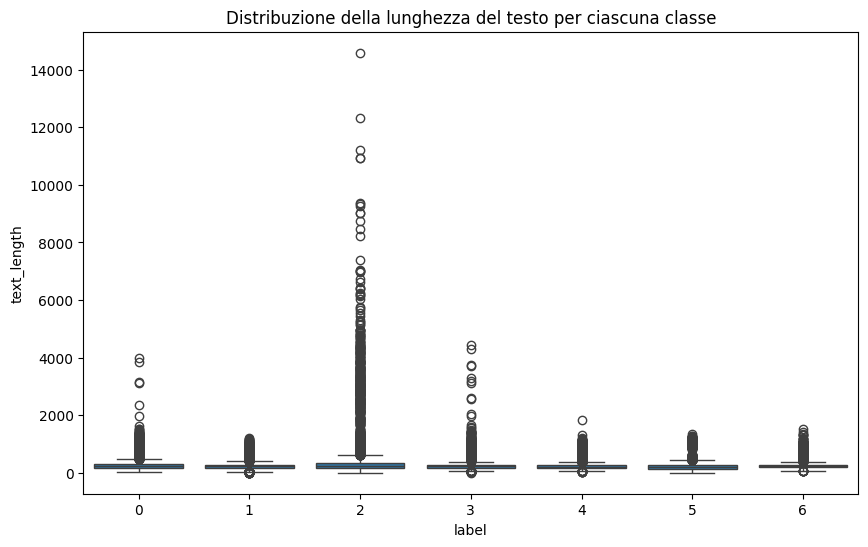

In [134]:
import seaborn as sns
plt.figure(figsize=(10,6))
sns.boxplot(x='label', y='text_length', data=train_df)
plt.title('Distribuzione della lunghezza del testo per ciascuna classe')        
plt.show()

## Linear SVC

In [ ]:
from sklearn.model_selection import StratifiedKFold


classifier = LinearSVC(random_state=42, max_iter=5000)
model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', classifier)
])


param_grid = {
    'clf__C': [0.2],
    'clf__class_weight': ['balanced'],
    'preprocessor__txt__min_df': [2],
    'preprocessor__txt__max_df': [0.3],
    'preprocessor__cat_source__encoder__max_categories': [300],
    'preprocessor__txt__ngram_range': [(1,4)],
    
}

cv_strategy= StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    model_pipeline, 
    param_grid, 
    cv=cv_strategy, 
    scoring='f1_macro', 
    n_jobs=-1, 
    verbose=2
)
grid_search.fit(X, y)
print("LINEAR SVC - Grid Search Results:")
print(grid_search.best_params_)
print(f"Best Cross-Validation Macro F1: {grid_search.best_score_:.4f}")
best_model = grid_search.best_estimator_



Fitting 5 folds for each of 1 candidates, totalling 5 fits


In [123]:
best_model.fit(X, y)
y_eval_pred = best_model.predict(X_eval)

pd.DataFrame({
    'Id': eval_df['Id'],
    'Predicted': y_eval_pred}).to_csv('submission.csv', index=False)

KeyboardInterrupt: 

# Logistic Regression

In [ ]:
classifier=LogisticRegression(random_state=42,max_iter=5000)

model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', classifier)
])

param_grid = {
    'clf__C': [0.1, 1, 10],
    'l1_ratio': [0.0, 1.0],
    'clf__solver': ['saga', 'liblinear'],
    'clf__class_weight': ['balanced'],
    'preprocessor__txt__ngram_range': [(1,3), (1,4)],
    'preprocessor__txt__min_df': [2, 3, 4, 5],
    'preprocessor__txt__max_df': [0.3, 0.4, 0.5, 0.6],
    'preprocessor__cat__max_categories': [100, 200, 300, 500]
}

cv_strategy= StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(
    model_pipeline,
    param_grid,
    cv=cv_strategy,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=2)

grid_search.fit(X, y)

print("LOGISTIC REGRESSION - Grid Search Results:")
print(grid_search.best_params_)
print(f"Best Cross-Validation Macro F1: {grid_search.best_score_:.4f}")
best_model = grid_search.best_estimator_

Fitting 5 folds for each of 1536 candidates, totalling 7680 fits


KeyboardInterrupt: 

In [ ]:
best_model.fit(X, y)
y_eval_pred = best_model.predict(X_eval)

pd.DataFrame({
    'Id': eval_df['Id'],
    'Predicted': y_eval_pred}).to_csv('submission.csv', index=False)

# GRAFICO

Splitting dataset...
Starting sensitivity analysis on max_features...
Testing max_features=5000...
Testing max_features=10000...
Testing max_features=20000...
Testing max_features=50000...
Testing max_features=100000...
Testing max_features=200000...
Testing max_features=300000...
Testing max_features=400000...
Testing max_features=500000...
Testing max_features=600000...
Testing max_features=700000...
Testing max_features=800000...
Testing max_features=900000...
Testing max_features=1000000...
Testing max_features=1200000...
Testing max_features=1500000...
Testing max_features=2000000...


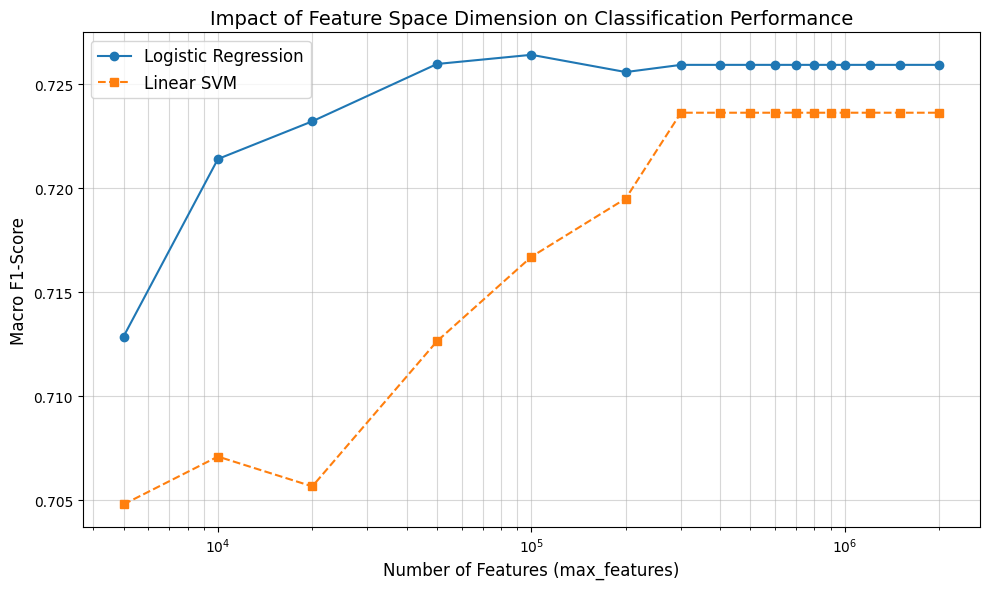

In [ ]:
# 1. Definizione dello split 80/20 (Hold-out strategy per l'analisi del parametro)
# È FONDAMENTALE usare stratify=y per mantenere le proporzioni delle classi
print("Splitting dataset...")
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Definizione dei valori da testare
# Consiglio accademico: usate una scala logaritmica o geometrica per coprire ordini di grandezza diversi.
# Testiamo da 1.000 a 300.000 feature. Oltre 100-200k raramente c'è guadagno in F1-Macro.
max_features_list = [5000, 10000, 20000, 50000, 100000, 200000, 300000, 400000, 500000, 600000, 700000, 800000, 900000, 1000000, 1200000, 1500000, 2000000]

scores_lr = []
scores_svm = []

print("Starting sensitivity analysis on max_features...")

for max_feat in max_features_list:
    print(f"Testing max_features={max_feat}...")
    
    # Ricostruiamo il preprocessor con il parametro corrente
    # NOTA: Assicuratevi che il preprocessor sia definito correttamente prima
    # Qui assumo una struttura standard basata sul vostro snippet
    
    preprocessor.set_params(txt__max_features=max_feat)
    preprocessor.set_params(txt__min_df=2)
    preprocessor.set_params(txt__max_df=0.5)

    # Pipeline SVM
    pipe_svm = Pipeline([
        ('preprocessor', preprocessor),
        ('clf', LinearSVC(class_weight='balanced', random_state=42))
    ])
    
    # Pipeline LogReg
    pipe_lr = Pipeline([
        ('preprocessor', preprocessor),
        ('clf', LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000))
    ])
    
    # Fit e Score su SVM
    pipe_svm.fit(X_train, y_train)
    y_pred_svm = pipe_svm.predict(X_val)
    scores_svm.append(f1_score(y_val, y_pred_svm, average='macro'))
    
    # Fit e Score su LogReg
    pipe_lr.fit(X_train, y_train)
    y_pred_lr = pipe_lr.predict(X_val)
    scores_lr.append(f1_score(y_val, y_pred_lr, average='macro'))

# 3. Plotting
plt.figure(figsize=(10, 6))
plt.plot(max_features_list, scores_lr, label='Logistic Regression', marker='o', linestyle='-')
plt.plot(max_features_list, scores_svm, label='Linear SVM', marker='s', linestyle='--')

plt.title('Impact of Feature Space Dimension on Classification Performance', fontsize=14)
plt.xlabel('Number of Features (max_features)', fontsize=12)
plt.ylabel('Macro F1-Score', fontsize=12)
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.legend(fontsize=12)
plt.xscale('log') # Fondamentale se spaziate molto i valori
plt.tight_layout()
plt.show()


In [ ]:
# ... (codice precedente invariato)

# 4. Identificazione dei migliori parametri
# Usiamo np.argmax per trovare l'indice del valore massimo
best_idx_svm = np.argmax(scores_svm)
best_score_svm = scores_svm[best_idx_svm]
best_feat_svm = max_features_list[best_idx_svm]

best_idx_lr = np.argmax(scores_lr)
best_score_lr = scores_lr[best_idx_lr]
best_feat_lr = max_features_list[best_idx_lr]

print("\n--- SENSITIVITY ANALYSIS RESULTS ---")
print(f"SVM: Best Macro F1 = {best_score_svm:.4f} using max_features = {best_feat_svm}")
print(f"LR:  Best Macro F1 = {best_score_lr:.4f} using max_features = {best_feat_lr}")

# Suggerimento del Professore: 
# Se la differenza tra lo score a 50k e 300k è < 0.001, 
# nel report giustificate l'uso di 50k per il principio di parsimonia.


--- SENSITIVITY ANALYSIS RESULTS ---
SVM: Best Macro F1 = 0.7285 using max_features = 1500000
LR:  Best Macro F1 = 0.7274 using max_features = 50000


# Grafico con max_df

Splitting dataset...
Starting sensitivity analysis on max_features...
Testing max_features=1000...
Testing max_features=5000...
Testing max_features=10000...
Testing max_features=20000...
Testing max_features=50000...
Testing max_features=100000...
Testing max_features=200000...
Testing max_features=300000...
Testing max_features=400000...
Testing max_features=500000...
Testing max_features=600000...
Testing max_features=700000...
Testing max_features=800000...
Testing max_features=900000...
Testing max_features=1000000...


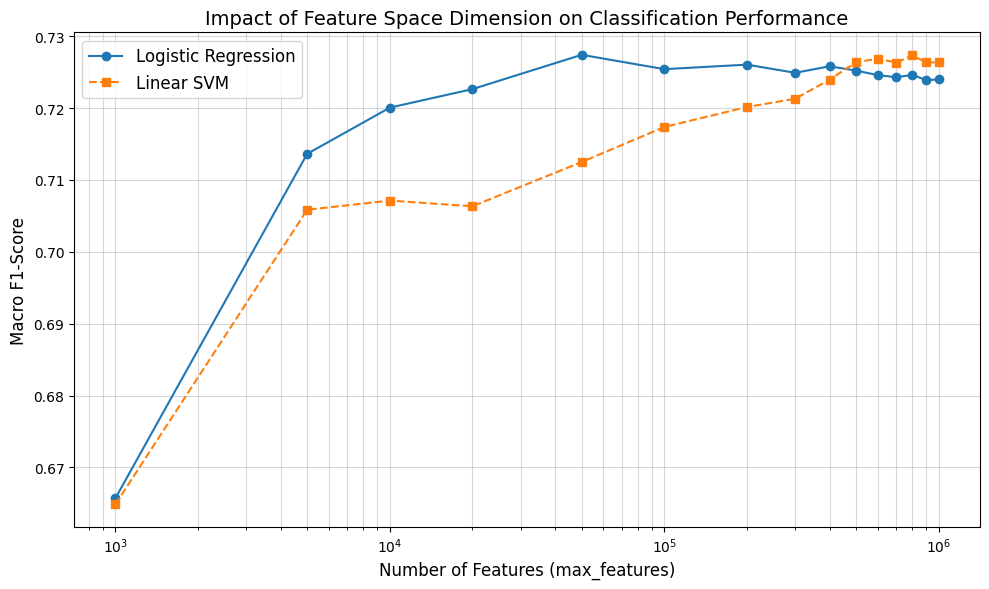

In [ ]:
# 1. Definizione dello split 80/20 (Hold-out strategy per l'analisi del parametro)
# È FONDAMENTALE usare stratify=y per mantenere le proporzioni delle classi
print("Splitting dataset...")
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Definizione dei valori da testare
# Consiglio accademico: usate una scala logaritmica o geometrica per coprire ordini di grandezza diversi.
# Testiamo da 1.000 a 300.000 feature. Oltre 100-200k raramente c'è guadagno in F1-Macro.
max_features_list = [1000, 5000, 10000, 20000, 50000, 100000, 200000, 300000, 400000, 500000, 600000, 700000, 800000, 900000, 1000000]

scores_lr = []
scores_svm = []

print("Starting sensitivity analysis on max_features...")

for max_feat in max_features_list:
    print(f"Testing max_features={max_feat}...")
    
    # Ricostruiamo il preprocessor con il parametro corrente
    # NOTA: Assicuratevi che il preprocessor sia definito correttamente prima
    # Qui assumo una struttura standard basata sul vostro snippet
    
    preprocessor.set_params(txt__max_features=max_feat)
    preprocessor.set_params(txt__max_df=0.5)
    
    # Pipeline SVM
    pipe_svm = Pipeline([
        ('preprocessor', preprocessor),
        ('clf', LinearSVC(class_weight='balanced', random_state=42, dual=False))
    ])
    
    # Pipeline LogReg
    pipe_lr = Pipeline([
        ('preprocessor', preprocessor),
        ('clf', LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000))
    ])
    
    # Fit e Score su SVM
    pipe_svm.fit(X_train, y_train)
    y_pred_svm = pipe_svm.predict(X_val)
    scores_svm.append(f1_score(y_val, y_pred_svm, average='macro'))
    
    # Fit e Score su LogReg
    pipe_lr.fit(X_train, y_train)
    y_pred_lr = pipe_lr.predict(X_val)
    scores_lr.append(f1_score(y_val, y_pred_lr, average='macro'))

# 3. Plotting
plt.figure(figsize=(10, 6))
plt.plot(max_features_list, scores_lr, label='Logistic Regression', marker='o', linestyle='-')
plt.plot(max_features_list, scores_svm, label='Linear SVM', marker='s', linestyle='--')

plt.title('Impact of Feature Space Dimension on Classification Performance', fontsize=14)
plt.xlabel('Number of Features (max_features)', fontsize=12)
plt.ylabel('Macro F1-Score', fontsize=12)
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.legend(fontsize=12)
plt.xscale('log') # Fondamentale se spaziate molto i valori
plt.tight_layout()
plt.show()

In [ ]:
# ... (codice precedente invariato)

# 4. Identificazione dei migliori parametri
# Usiamo np.argmax per trovare l'indice del valore massimo
best_idx_svm = np.argmax(scores_svm)
best_score_svm = scores_svm[best_idx_svm]
best_feat_svm = max_features_list[best_idx_svm]

best_idx_lr = np.argmax(scores_lr)
best_score_lr = scores_lr[best_idx_lr]
best_feat_lr = max_features_list[best_idx_lr]

print("\n--- SENSITIVITY ANALYSIS RESULTS ---")
print(f"SVM: Best Macro F1 = {best_score_svm:.4f} using max_features = {best_feat_svm}")
print(f"LR:  Best Macro F1 = {best_score_lr:.4f} using max_features = {best_feat_lr}")

# Suggerimento del Professore: 
# Se la differenza tra lo score a 50k e 300k è < 0.001, 
# nel report giustificate l'uso di 50k per il principio di parsimonia.


--- SENSITIVITY ANALYSIS RESULTS ---
SVM: Best Macro F1 = 0.7273 using max_features = 800000
LR:  Best Macro F1 = 0.7274 using max_features = 50000


In [ ]:
preprocessor.set_params(
    txt__max_features=best_feat_lr,
    txt__ngram_range=(1, 3),
    # Assicuriamoci che gli altri siano quelli standard usati nel loop
    txt__stop_words='english',
    txt__sublinear_tf=True
)

# 2. Configura il Modello "Campione" (Logistic Regression Default)
# Usiamo C=1.0 perché nel loop della sensitivity analysis non avevi cambiato C.
# max_iter=1000 serve per evitare i warning di convergenza.
final_model = LogisticRegression(
    class_weight='balanced', 
    random_state=42,     # Default
    max_iter=1000      # Per sicurezza
)

# 3. Crea la Pipeline Finale
submission_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', final_model)
])

# 4. Addestramento su TUTTO il dataset di sviluppo (X, y)
# Non usare X_train, vogliamo sfruttare ogni singola riga di dati disponibile.
print("Addestramento del modello finale su tutto il dataset (100% dati)...")
submission_pipeline.fit(X, y)

# 5. Predizione sull'Evaluation Set (X_eval)
print("Predizione sull'Evaluation Set...")
y_eval_pred = submission_pipeline.predict(X_eval)

# 6. Creazione del file di sottomissione
print("Generazione file submission.csv...")
submission_df = pd.DataFrame({
    'Id': eval_df['Id'],
    'Predicted': y_eval_pred
})

submission_df.to_csv('submission.csv', index=False)
print("Fatto! File 'submission.csv' pronto per la leaderboard.")

Addestramento del modello finale su tutto il dataset (100% dati)...
Predizione sull'Evaluation Set...
Generazione file submission.csv...
Fatto! File 'submission.csv' pronto per la leaderboard.


In [ ]:
preprocessor.set_params(
    txt__max_features=best_feat_svm,
    txt__ngram_range=(1, 3),
    # Assicuriamoci che gli altri siano quelli standard usati nel loop
    txt__stop_words='english',
    txt__sublinear_tf=True
)

# 2. Configura il Modello "Campione" (Logistic Regression Default)
# Usiamo C=1.0 perché nel loop della sensitivity analysis non avevi cambiato C.
# max_iter=1000 serve per evitare i warning di convergenza.
final_model = LinearSVC(
    class_weight='balanced', 
    random_state=42,     # Default
)

# 3. Crea la Pipeline Finale
submission_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', final_model)
])

# 4. Addestramento su TUTTO il dataset di sviluppo (X, y)
# Non usare X_train, vogliamo sfruttare ogni singola riga di dati disponibile.
print("Addestramento del modello finale su tutto il dataset (100% dati)...")
submission_pipeline.fit(X, y)

# 5. Predizione sull'Evaluation Set (X_eval)
print("Predizione sull'Evaluation Set...")
y_eval_pred = submission_pipeline.predict(X_eval)

# 6. Creazione del file di sottomissione
print("Generazione file submission.csv...")
submission_df = pd.DataFrame({
    'Id': eval_df['Id'],
    'Predicted': y_eval_pred
})

submission_df.to_csv('submission.csv', index=False)
print("Fatto! File 'submission.csv' pronto per la leaderboard.")

Addestramento del modello finale su tutto il dataset (100% dati)...
Predizione sull'Evaluation Set...
Generazione file submission.csv...
Fatto! File 'submission.csv' pronto per la leaderboard.


In [ ]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression

# 1. Configurazione Preprocessor (come nel tuo codice originale)
preprocessor.set_params(txt__max_df=0.3)

# 2. Definizione dei Pipeline
pipe_svm = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', LinearSVC(class_weight='balanced', random_state=42))
])

pipe_lr = Pipeline([
    ('preprocessor', preprocessor),
    ('clf', LogisticRegression(class_weight='balanced', random_state=42, max_iter=10000))
])

# 3. Configurazione della Strategia di Cross-Validation
# StratifiedKFold mantiene la proporzione delle classi in ogni fold (essenziale per classificazione)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ---------------------------------------------------------
# ESECUZIONE SVM
# ---------------------------------------------------------
print("--- Report SVM (5-Fold CV) ---")
# cross_val_predict allena il modello 5 volte e restituisce le predizioni
y_pred_svm = cross_val_predict(pipe_svm, X, y, cv=cv, n_jobs=-1)
print(classification_report(y, y_pred_svm))

# ---------------------------------------------------------
# ESECUZIONE LOGISTIC REGRESSION
# ---------------------------------------------------------
print("--- Report Logistic Regression (5-Fold CV) ---")
y_pred_lr = cross_val_predict(pipe_lr, X, y, cv=cv, n_jobs=-1)
print(classification_report(y, y_pred_lr))

--- Report SVM (5-Fold CV) ---
              precision    recall  f1-score   support

           0       0.77      0.78      0.77     22364
           1       0.76      0.83      0.79     10102
           2       0.84      0.84      0.84     10644
           3       0.64      0.54      0.58      9038
           4       0.83      0.93      0.88      8359
           5       0.57      0.48      0.52     11196
           6       0.62      0.76      0.68      2826

    accuracy                           0.74     74529
   macro avg       0.72      0.74      0.72     74529
weighted avg       0.73      0.74      0.73     74529

--- Report Logistic Regression (5-Fold CV) ---
              precision    recall  f1-score   support

           0       0.82      0.71      0.76     22364
           1       0.75      0.83      0.79     10102
           2       0.86      0.83      0.84     10644
           3       0.60      0.57      0.58      9038
           4       0.82      0.93      0.87      8359


In [ ]:
# 1. Definizione dello split 80/20 (Hold-out strategy per l'analisi del parametro)
# È FONDAMENTALE usare stratify=y per mantenere le proporzioni delle classi
print("Splitting dataset...")
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Definizione dei valori da testare
# Consiglio accademico: usate una scala logaritmica o geometrica per coprire ordini di grandezza diversi.
# Testiamo da 1.000 a 300.000 feature. Oltre 100-200k raramente c'è guadagno in F1-Macro.
max_df_list = [2,3,4,5,6,7,8,9,10]

scores_lr = []
scores_svm = []

print("Starting sensitivity analysis on max_features...")

for max_df in max_df_list:
    print(f"Testing max_features={max_df}...")
    
    # Ricostruiamo il preprocessor con il parametro corrente
    # NOTA: Assicuratevi che il preprocessor sia definito correttamente prima
    # Qui assumo una struttura standard basata sul vostro snippet
    
    preprocessor.set_params(txt__min_df=max_df)
    preprocessor.set_params(txt__max_df=0.3)

    # Pipeline SVM
    pipe_svm = Pipeline([
        ('preprocessor', preprocessor),
        ('clf', LinearSVC(class_weight='balanced', random_state=42))
    ])
    
    # Pipeline LogReg
    pipe_lr = Pipeline([
        ('preprocessor', preprocessor),
        ('clf', LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000))
    ])
    
    # Fit e Score su SVM
    pipe_svm.fit(X_train, y_train)
    y_pred_svm = pipe_svm.predict(X_val)
    scores_svm.append(f1_score(y_val, y_pred_svm, average='macro'))
    
    # Fit e Score su LogReg
    pipe_lr.fit(X_train, y_train)
    y_pred_lr = pipe_lr.predict(X_val)
    scores_lr.append(f1_score(y_val, y_pred_lr, average='macro'))



Splitting dataset...
Starting sensitivity analysis on max_features...
Testing max_features=2...
Testing max_features=3...
Testing max_features=4...
Testing max_features=5...
Testing max_features=6...
Testing max_features=7...
Testing max_features=8...
Testing max_features=9...
Testing max_features=10...


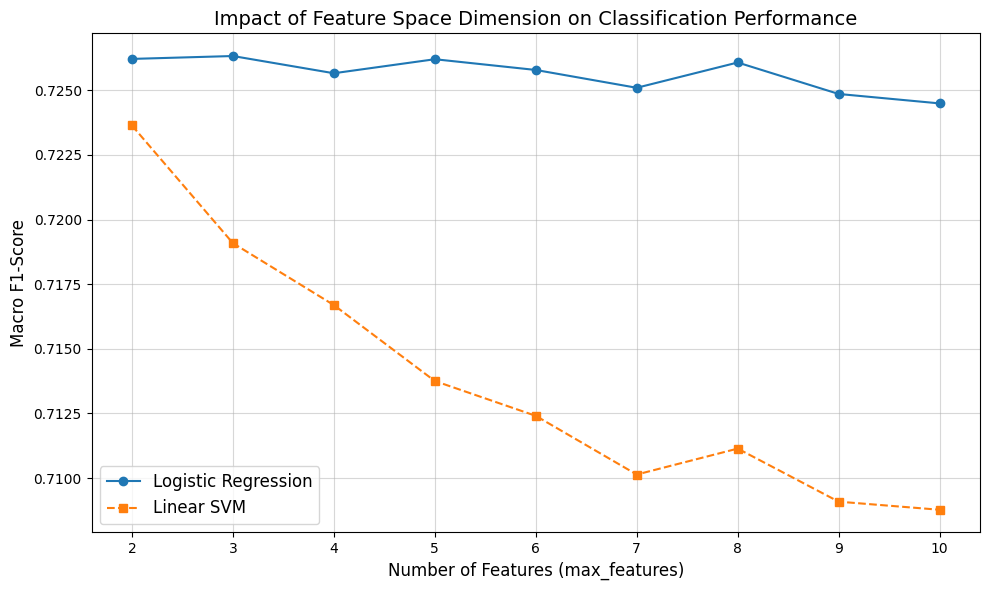

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(max_df_list, scores_lr, label='Logistic Regression', marker='o', linestyle='-')
plt.plot(max_df_list, scores_svm, label='Linear SVM', marker='s', linestyle='--')

plt.title('Impact of Feature Space Dimension on Classification Performance', fontsize=14)
plt.xlabel('Number of Features (max_features)', fontsize=12)
plt.ylabel('Macro F1-Score', fontsize=12)
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.legend(fontsize=12)
#plt.xscale('log') # Fondamentale se spaziate molto i valori
plt.tight_layout()
plt.show()

In [ ]:
# 1. Definizione dello split 80/20 (Hold-out strategy per l'analisi del parametro)
# È FONDAMENTALE usare stratify=y per mantenere le proporzioni delle classi
print("Splitting dataset...")
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Definizione dei valori da testare
# Consiglio accademico: usate una scala logaritmica o geometrica per coprire ordini di grandezza diversi.
# Testiamo da 1.000 a 300.000 feature. Oltre 100-200k raramente c'è guadagno in F1-Macro.
max_categories_list = [10, 50, 100, 150, 200, 250, 300, 350, 400, 500, 600, 700, 800, 900, 1000, 1100, 1200]

scores_lr = []
scores_svm = []

print("Starting sensitivity analysis on max_features...")

for max_categories in max_categories_list:
    print(f"Testing max_categories={max_categories}...")
    
    # Ricostruiamo il preprocessor con il parametro corrente
    # NOTA: Assicuratevi che il preprocessor sia definito correttamente prima
    # Qui assumo una struttura standard basata sul vostro snippet
    
    preprocessor.set_params(cat_source__encoder__max_categories=max_categories)

    # Pipeline SVM
    pipe_svm = Pipeline([
        ('preprocessor', preprocessor),
        ('clf', LinearSVC(class_weight='balanced', random_state=42))
    ])
    
    # Pipeline LogReg
    pipe_lr = Pipeline([
        ('preprocessor', preprocessor),
        ('clf', LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000))
    ])
    
    # Fit e Score su SVM
    pipe_svm.fit(X_train, y_train)
    y_pred_svm = pipe_svm.predict(X_val)
    scores_svm.append(f1_score(y_val, y_pred_svm, average='macro'))
    
    # Fit e Score su LogReg
    pipe_lr.fit(X_train, y_train)
    y_pred_lr = pipe_lr.predict(X_val)
    scores_lr.append(f1_score(y_val, y_pred_lr, average='macro'))



Splitting dataset...
Starting sensitivity analysis on max_features...
Testing max_categories=10...
Testing max_categories=50...
Testing max_categories=100...
Testing max_categories=150...
Testing max_categories=200...
Testing max_categories=250...
Testing max_categories=300...
Testing max_categories=350...
Testing max_categories=400...
Testing max_categories=500...
Testing max_categories=600...
Testing max_categories=700...
Testing max_categories=800...
Testing max_categories=900...
Testing max_categories=1000...
Testing max_categories=1100...
Testing max_categories=1200...


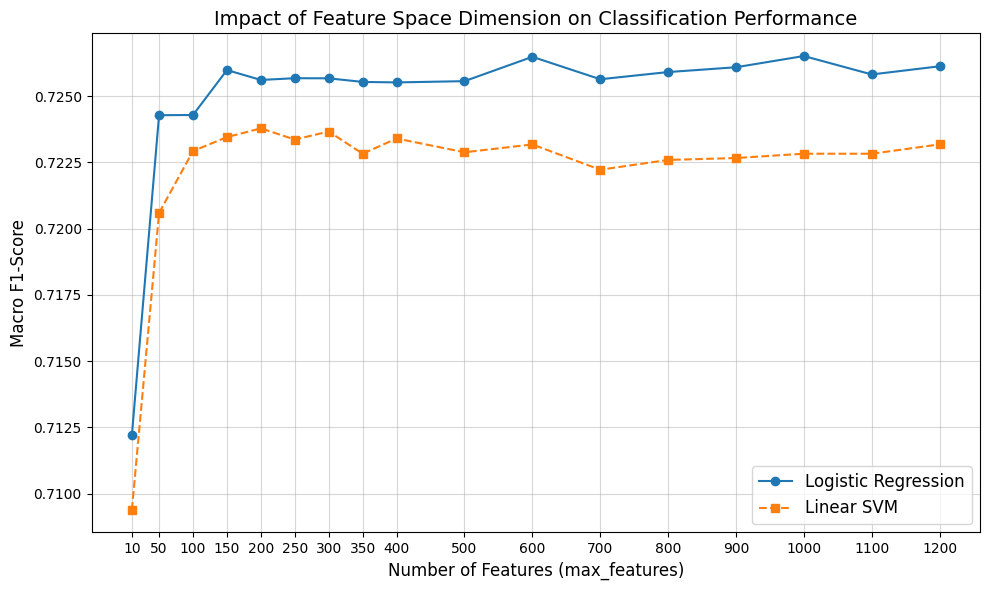

[0.7122213549977332, 0.7242816771503756, 0.724289262013665, 0.7259856221192116, 0.7256127459545307, 0.7256785895441341, 0.7256737976847247, 0.7255380701403439, 0.7255195593319163, 0.7255670750943476, 0.7264853156023136, 0.7256393030970589, 0.7259103380650638, 0.7260919126316583, 0.7265158596198473, 0.7258201543273405, 0.7261283660317899]
[0.7093884604117465, 0.7205930912915758, 0.7229292332274594, 0.7234550002356369, 0.7237850304269411, 0.7233634641850845, 0.723665471196843, 0.7228283257213939, 0.7234028110569077, 0.7228824340667673, 0.723178166009056, 0.7222231438515146, 0.72259390721309, 0.7226652582114342, 0.7228282663407636, 0.7228269208536064, 0.7231812975391628]


In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(max_categories_list, scores_lr, label='Logistic Regression', marker='o', linestyle='-')
plt.plot(max_categories_list, scores_svm, label='Linear SVM', marker='s', linestyle='--')

plt.title('Impact of Feature Space Dimension on Classification Performance', fontsize=14)
plt.xlabel('Number of Features (max_features)', fontsize=12)
plt.ylabel('Macro F1-Score', fontsize=12)
plt.grid(True, which="both", ls="-", alpha=0.5)
plt.legend(fontsize=12)
plt.xticks(max_categories_list)
#plt.xscale('log') # Fondamentale se spaziate molto i valori
plt.tight_layout()
plt.show()

print(scores_lr)
print(scores_svm)